# Third-generation unary terms: Einstein and two-state

Third-generation CALPHAD descriptions model a phase down to 0 K, with terms
that each have a physical meaning:

- an **Einstein solid** for the harmonic vibrations,
  $$G_E = \tfrac{3}{2} R\theta_E + 3RT \ln\left(1 - e^{-\theta_E/T}\right).$$
  The TDB stores ln θ_E (`THETA`), so the composition dependence is
  Redlich–Kister in ln θ_E;
- the **two-state model** for the liquid–amorphous transition,
  $$G_\mathrm{2st} = -RT \ln\left(1 + e^{-\Delta G_d / RT}\right).$$
  Each atom is solid-like (amorphous) or liquid-like. ΔG_d (`GD`) is the energy
  of the change, and 1 / (1 + e^{ΔG_d/RT}) is the fraction of liquid-like
  atoms. Below the glass transition the liquid becomes an amorphous solid.

Both terms increase with their argument, and so do their derivatives' bounds,
so their interval enclosures are exact and certification is unaffected.

This notebook uses pycalphad's test database `femn.tdb` ("for testing purposes
only"): one Fe–Mn liquid with Xiong magnetism, Einstein and two-state terms,
and no interaction parameters.

References:

- J. Ågren, *Thermodynamics of supercooled liquids and their glass
  transition*, Phys. Chem. Liq. 18 (1988) 123–139 (the two-state model);
- J. Ågren, B. Cheynet, M. T. Clavaguera-Mora, K. Hack, J. Hertz, F. Sommer and
  U. Kattner, *Workshop on thermodynamic models and data for pure elements and
  other endmembers of solutions*, Calphad 19 (1995) 449–480;
- Q. Chen and B. Sundman, *Modeling of thermodynamic properties for Bcc, Fcc,
  liquid, and amorphous iron*, J. Phase Equilib. 22 (2001) 631–644;
- W. Xiong et al., Calphad 39 (2012) 11–20 (the magnetic model).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pycalphad

from discopt.calphad import CertificateLevel, ThermoDatabase, equilibrium
from discopt.calphad.equilibrium.common import R_GAS
from discopt.calphad.models.lattice import einstein, two_state
from discopt.calphad.ops import NUM

TDB = Path(pycalphad.__file__).parent / "tests" / "databases" / "femn.tdb"
db = ThermoDatabase.from_tdb(TDB)
print(db.applicability(("FE", "MN")))
liq = db.phase_model("LIQUID", ("FE", "MN"))
print("THETA terms:", [t.label for t in liq.einstein])
print("GD terms:   ", [t.label for t in liq.two_state])
print("magnetism:  ", "Xiong" if liq.magnetic.xiong else "IHJ")

{'LIQUID': 'ok'}
THETA terms: ['FE:VA;0', 'MN:VA;0']
GD terms:    ['FE:VA;0', 'MN:VA;0']
magnetism:   Xiong


In [2]:
def u_of(yfe):
    return liq.variables_from_site_fractions([{"FE": yfe, "MN": 1 - yfe}, {"VA": 1.0}])


def parts(yfe, T):
    """G and its parts in J/mol, at site fraction ``yfe`` of Fe."""
    Y = liq._Y(np.asarray(u_of(yfe)))
    RT = R_GAS * T
    ein = float(einstein(liq._sum(liq.einstein, Y, T), T, NUM)) * RT
    gd = float(liq._sum(liq.two_state, Y, T))
    out = {
        "total": float(liq.gibbs(u_of(yfe), NUM, T)) * RT,
        "Einstein": ein,
        "two-state": float(two_state(gd, T, NUM)) * RT,
        "magnetic": float(liq.magnetic_at(Y, T, NUM)) * RT,
        "gd": gd,
    }
    return out

## Pure liquid (and amorphous) Fe from 20 to 2500 K

   500 K: liquid-like fraction 0.000, C_p = 26.6 J/mol/K
  1000 K: liquid-like fraction 0.035, C_p = 36.5 J/mol/K
  1811 K: liquid-like fraction 0.281, C_p = 47.1 J/mol/K
  2500 K: liquid-like fraction 0.470, C_p = 45.2 J/mol/K


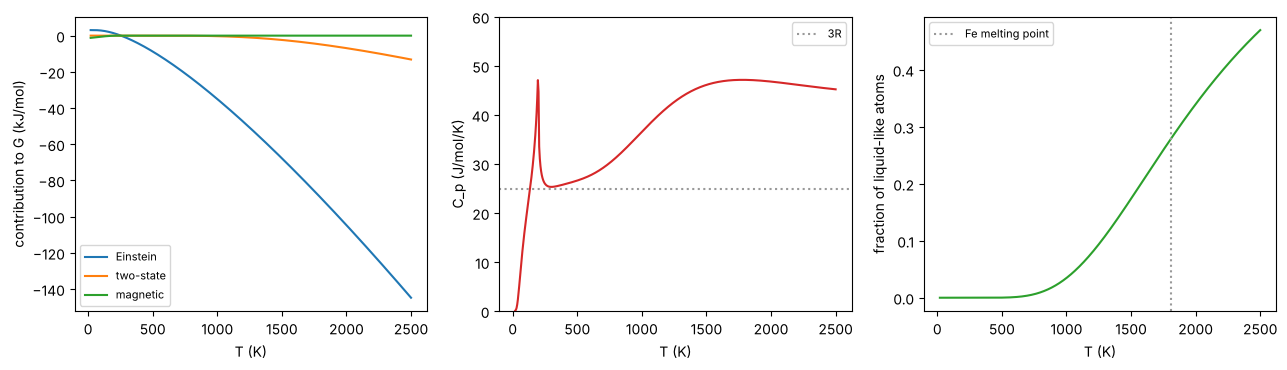

In [3]:
TS = np.linspace(20.0, 2500.0, 497)
P = [parts(1.0, T) for T in TS]
h = 0.5
cp = np.array(
    [-T * (parts(1.0, T + h)["total"] - 2 * parts(1.0, T)["total"] + parts(1.0, T - h)["total"]) / h**2 for T in TS]
)
liquid_like = np.array([1 / (1 + np.exp(p["gd"] / (R_GAS * T))) for p, T in zip(P, TS)])
for T in (500.0, 1000.0, 1811.0, 2500.0):
    i = np.searchsorted(TS, T)
    print(f"{T:6.0f} K: liquid-like fraction {liquid_like[i]:.3f}, C_p = {cp[i]:.1f} J/mol/K")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for k in ("Einstein", "two-state", "magnetic"):
    axes[0].plot(TS, [p[k] / 1000 for p in P], label=k)
axes[0].set_ylabel("contribution to G (kJ/mol)")
axes[0].legend(fontsize=8)
axes[1].plot(TS, cp, color="C3")
axes[1].axhline(3 * R_GAS, color="0.6", ls=":", label="3R")
axes[1].set_ylim(0, 60)
axes[1].set_ylabel("C_p (J/mol/K)")
axes[1].legend(fontsize=8)
axes[2].plot(TS, liquid_like, color="C2")
axes[2].axvline(1811, color="0.6", ls=":", label="Fe melting point")
axes[2].set_ylabel("fraction of liquid-like atoms")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("T (K)")
fig.tight_layout()
plt.show()

C_p rises to about 3R (Dulong–Petit) as the Einstein vibrations switch on,
then climbs through a broad hump as atoms turn liquid-like. The sharp peak at
200 K is the magnetic transition: this test file gives liquid Fe T_C = 200 K.

## G against pycalphad

pycalphad's gas constant is 8.3145 J/(mol K); this package uses the CODATA
value. The terms that carry R are rescaled for the comparison.

In [4]:
from pycalphad import Database, calculate  # noqa: E402

pdb = Database(str(TDB))
worst = 0.0
for T in (300.0, 1000.0, 1800.0, 2500.0):
    for yfe in np.linspace(0.05, 0.95, 7):
        ref = float(
            calculate(
                pdb, ["FE", "MN", "VA"], "LIQUID", T=T, P=101325, N=1, points=np.array([[yfe, 1 - yfe, 1.0]])
            ).GM.values.squeeze()
        )
        p = parts(yfe, T)
        ideal = float(liq.ideal_at(liq._Y(np.asarray(u_of(yfe))), NUM))
        ours = p["total"] + (8.3145 - R_GAS) * T * (ideal + (p["Einstein"] + p["magnetic"]) / (R_GAS * T))
        ours += -8.3145 * T * np.logaddexp(0, -p["gd"] / (8.3145 * T)) - p["two-state"]
        worst = max(worst, abs(ours - ref) / abs(ref))
print(f"largest relative difference from pycalphad.calculate: {worst:.1e}")

largest relative difference from pycalphad.calculate: 1.0e-15


## Certified equilibria

In [5]:
certified = 0
for T in (600.0, 1200.0, 1800.0):
    for x in (0.1, 0.5, 0.9):
        r = equilibrium([liq], x=x, T=T)
        certified += r.certificate.level >= CertificateLevel.CERTIFIED_TO_TOLERANCE
        print(f"{T:6.0f} K, x(Fe) = {x}: {r.certificate.level.name}, {len(r.composition_sets)} liquid set(s)")
print(f"{certified} of 9 certified")

   600 K, x(Fe) = 0.1: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


   600 K, x(Fe) = 0.5: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


   600 K, x(Fe) = 0.9: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


  1200 K, x(Fe) = 0.1: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


  1200 K, x(Fe) = 0.5: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


  1200 K, x(Fe) = 0.9: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


  1800 K, x(Fe) = 0.1: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


  1800 K, x(Fe) = 0.5: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)


  1800 K, x(Fe) = 0.9: CERTIFIED_TO_TOLERANCE, 1 liquid set(s)
9 of 9 certified
